# Lab 11-03 · Convolution

Companion to [chapter 11-03](../../chapters/11-03-convolution.md). Five parts: convolution four ways, graphical convolution, an RC circuit by convolution, an ADC's decimation filter, and a matched filter. Run the cells in order.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import toeplitz
from scipy.integrate import solve_ivp

rng = np.random.default_rng(1103)

## Part 1 — Convolution four ways

A double loop (the definition), `np.convolve`, a Toeplitz matrix product and polynomial multiplication must all agree.

In [2]:
def conv_loop(x, h):
    y = np.zeros(len(x) + len(h) - 1)
    for n in range(len(y)):
        for k in range(len(x)):
            if 0 <= n - k < len(h):
                y[n] += x[k] * h[n - k]
    return y

def conv_toeplitz(x, h):
    L = len(x) + len(h) - 1
    col = np.r_[h, np.zeros(L - len(h))]
    row = np.r_[h[0], np.zeros(len(x) - 1)]
    return toeplitz(col, row) @ x            # L x len(x) matrix, constant along diagonals

def conv_poly(x, h):
    return np.polynomial.polynomial.polymul(x, h)

x, h = np.array([1.0, 2, 3]), np.array([1.0, -1, 2])
for f in (conv_loop, np.convolve, conv_toeplitz, conv_poly):
    print(f"{f.__name__:14s}", f(x, h))

xr, hr = rng.normal(size=50), rng.normal(size=12)
ref = conv_loop(xr, hr)
worst = max(np.max(np.abs(f(xr, hr) - ref)) for f in (np.convolve, conv_toeplitz, conv_poly))
print("largest disagreement on random sequences:", worst)
assert worst < 1e-12

conv_loop      [1. 1. 3. 1. 6.]
convolve       [1. 1. 3. 1. 6.]
conv_toeplitz  [1. 1. 3. 1. 6.]
conv_poly      [1. 1. 3. 1. 6.]
largest disagreement on random sequences: 1.7763568394002505e-15


## Part 2 — Graphical convolution, numerically

Sample the two pulses of Example 11-03.3 on a grid of step Δ and approximate the integral by a sum times Δ.

y(0.5) = 1.5030
y(1.5) = 3.0000
y(2.5) = 1.4970
area = 6.0000


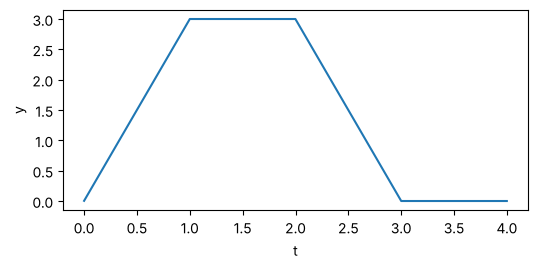

In [3]:
dt = 1e-3
t = np.arange(0, 4, dt)
xp = ((t >= 0) & (t < 2)).astype(float)
hp = 3.0 * ((t >= 0) & (t < 1))
yp = np.convolve(xp, hp)[: len(t)] * dt
for tt in (0.5, 1.5, 2.5):
    print(f"y({tt}) = {yp[int(round(tt / dt))]:.4f}")
print(f"area = {yp.sum() * dt:.4f}")
plt.figure(figsize=(6, 2.6)); plt.plot(t, yp); plt.xlabel("t"); plt.ylabel("y"); plt.show()

## Part 3 — An RC circuit by convolution (guided exercise)

**Predict first:** the convolution integral of Example 11-03.4 is computed as a sum with step Δ. How does the error at $t$ = 2 ms change when Δ is halved, with the rectangle rule and with the trapezoidal rule? Then run the cell.

In [4]:
tau = 1e-3
exact = 5 * (1 - np.exp(-2))                            # y(2 ms) from the chapter

def y_at_2ms(dlt, rule):
    lam = np.arange(0, 2e-3 + dlt / 2, dlt)              # integration points from 0 to 2 ms
    f = 5.0 * np.exp(-(2e-3 - lam) / tau) / tau          # x(lam) h(2 ms - lam)
    if rule == "rectangle":
        return np.sum(f[:-1]) * dlt                       # left endpoints
    return (np.sum(f) - 0.5 * (f[0] + f[-1])) * dlt       # trapezoid

errs = {}
for rule in ("rectangle", "trapezoid"):
    e1 = abs(y_at_2ms(2e-5, rule) - exact)
    e2 = abs(y_at_2ms(1e-5, rule) - exact)
    errs[rule] = e1 / e2
    print(f"{rule:9s}: error {e1:.2e} V -> {e2:.2e} V when the step halves (ratio {e1 / e2:.2f})")

# cross-check against the circuit's ODE, tau dy/dt + y = x
sol = solve_ivp(lambda tt, yy: [((5.0 if tt < 2e-3 else 0.0) - yy[0]) / tau], (0, 2e-3), [0.0],
                rtol=1e-10, atol=1e-12)
print(f"ODE: y(2 ms) = {sol.y[0, -1]:.4f} V; convolution formula: {exact:.4f} V")

rectangle: error 4.31e-02 V -> 2.16e-02 V when the step halves (ratio 2.00)
trapezoid: error 1.44e-04 V -> 3.60e-05 V when the step halves (ratio 4.00)
ODE: y(2 ms) = 4.3233 V; convolution formula: 4.3233 V


## Part 4 — The ADS1292R's decimation filter

Build the third-order sinc filter as three cascaded 256-sample boxcars, normalize it to unity DC gain, and find its step response.

length: 766 samples = 5.984 ms
DC gain after normalization: 1.000000
step response after one output period (256 samples): 0.1686
50% point: sample 382 (centre of h at 382.5), 2.988 ms


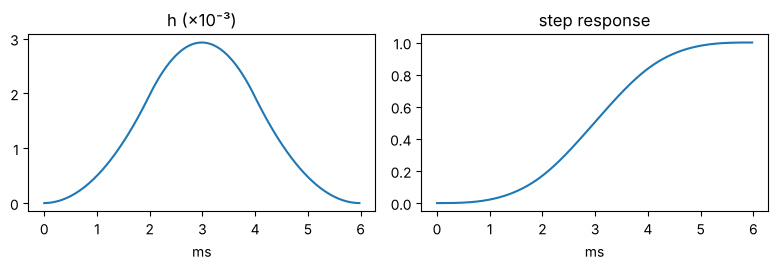

In [5]:
N = 256
box = np.ones(N)
h3 = np.convolve(np.convolve(box, box), box) / N ** 3
s3 = np.cumsum(h3)
fmod = 128e3
print("length:", len(h3), "samples =", round(len(h3) / fmod * 1e3, 3), "ms")
print(f"DC gain after normalization: {h3.sum():.6f}")
print(f"step response after one output period (256 samples): {s3[N - 1]:.4f}")
half = np.argmax(s3 >= 0.5)
print(f"50% point: sample {half} (centre of h at {(len(h3) - 1) / 2}), {(len(h3) - 1) / 2 / fmod * 1e3:.3f} ms")
fig, ax = plt.subplots(1, 2, figsize=(8, 2.8))
ax[0].plot(np.arange(len(h3)) / fmod * 1e3, h3 * 1e3); ax[0].set_xlabel("ms"); ax[0].set_title("h (×10⁻³)")
ax[1].plot(np.arange(len(h3)) / fmod * 1e3, s3); ax[1].set_xlabel("ms"); ax[1].set_title("step response")
plt.tight_layout(); plt.show()

## Part 5 — A matched filter

Hide the three-chip pattern $p = 1, 1, -1$ (repeated as a longer code) in noise and find it by convolving with the reversed pattern.

pattern inserted at 137 ; matched filter peaks at 137
Barker-3 autocorrelation: [-1.  0.  3.  0. -1.]


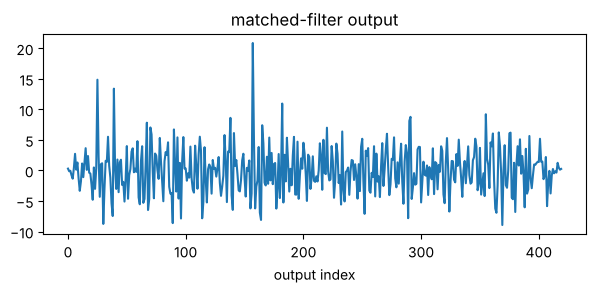

In [6]:
p = np.array([1.0, 1.0, -1.0])
code_ = np.kron([1, 1, 1, -1, -1, 1, -1], p)            # a longer pattern built from p
true_start = 137
r = rng.normal(0, 0.8, size=400)
r[true_start:true_start + len(code_)] += code_
mf = np.convolve(r, code_[::-1])                      # matched filter = convolve with the reversed pattern
detected = int(np.argmax(mf)) - (len(code_) - 1)
print("pattern inserted at", true_start, "; matched filter peaks at", detected)
print("Barker-3 autocorrelation:", np.convolve(p, p[::-1]))
plt.figure(figsize=(7, 2.6)); plt.plot(mf); plt.xlabel("output index"); plt.title("matched-filter output"); plt.show()

**What to take away.** Convolution is one operation with many faces: a double loop, a library call, a matrix product and a polynomial product. Numerically it is a Riemann sum, with the error of whatever integration rule you use. Cascades are convolutions (three boxcars make the sinc³ filter, whose length sets its latency), and a convolution with a reversed pattern is a detector.